# NN_L12_fewshot_curve

**Macro-F1 on Financial PhraseBank of Qwen2.5-1.5B and 3B with 0, 3, 6, 12 and 24 balanced examples in the prompt (three seeds for the choice of examples), against TF-IDF with logistic regression.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_fewshot_curve/NN_L12_fewshot_curve.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

1.5B, 0 examples: mean macro-F1 = 85.1   [fewshot.15B.0.mean]
1.5B, 3 examples: mean macro-F1 = 87.3   [fewshot.15B.1.mean]
1.5B, 6 examples: mean macro-F1 = 86.0   [fewshot.15B.2.mean]
1.5B, 12 examples: mean macro-F1 = 85.9   [fewshot.15B.4.mean]
1.5B, 24 examples: mean macro-F1 = 84.1   [fewshot.15B.8.mean]
3B, 0 examples: mean macro-F1 = 92.2   [fewshot.3B.0.mean]
3B, 3 examples: mean macro-F1 = 89.5   [fewshot.3B.1.mean]
3B, 6 examples: mean macro-F1 = 90.4   [fewshot.3B.2.mean]
3B, 12 examples: mean macro-F1 = 92.1   [fewshot.3B.4.mean]
3B, 24 examples: mean macro-F1 = 91.3   [fewshot.3B.8.mean]


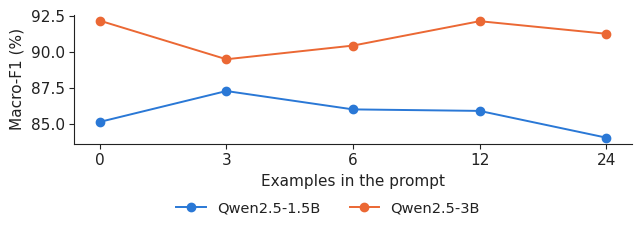

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from sklearn.metrics import f1_score, accuracy_score
LAB = {'pb': ['positive', 'negative', 'neutral'], 'tw': ['bullish', 'bearish', 'neutral']}
def f1(y, p, ds):
    return f1_score(y, p, labels=LAB[ds], average='macro')
def pred(df, m, ds):
    P = df[[f'{m}_{l}' for l in LAB[ds]]].values
    return [LAB[ds][i] for i in P.argmax(1)]
L = pd.read_csv(RES + 'fewshot_labels_pb.csv')
KS = [0, 1, 2, 4, 8]
mean = {}
for s in ('1.5B', '3B'):
    for k in KS:
        v = [100 * f1(L.label, L[f'{s}_k{k}_s{sd}'], 'pb') for sd in (0, 1, 2)]
        mean[(s, k)] = np.mean(v)
        show('fewshot.' + s.replace('.', '') + f'.{k}.mean', f'{s}, {3 * k} examples: mean macro-F1', round(float(np.mean(v)), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for s, c in (('1.5B', PAL['data']), ('3B', PAL['model'])):
    ax.plot(range(5), [mean[(s, k)] for k in KS], marker='o', color=c, label='Qwen2.5-' + s)
ax.set_xticks(range(5))
ax.set_xticklabels([str(3 * k) for k in KS])
ax.set_xlabel('Examples in the prompt')
ax.set_ylabel('Macro-F1 (%)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('fewshot_curve.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()